# UCI HAR : classification sur signal brut

on classe l'activite (6 classes : marche, montee, descente, assis, debout, couche). le decoupage d'UCI HAR separe deja les sujets (21 en train, 9 en test), donc source = sujets d'entrainement, cible = sujets de test.

In [11]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from adapt_utils import predict, split_har, courbe_apprentissage, comparer_adapt, barres_adapt

## chargement

In [12]:
data_dir = "../../data/UCI HAR Dataset"

canaux = ["body_acc_x", "body_acc_y", "body_acc_z",
          "body_gyro_x", "body_gyro_y", "body_gyro_z",
          "total_acc_x", "total_acc_y", "total_acc_z"]

def charger_signaux(split):
    signaux = [np.loadtxt(f"{data_dir}/{split}/Inertial Signals/{c}_{split}.txt") for c in canaux]
    return np.hstack(signaux)

Xs = charger_signaux("train")
ys = np.loadtxt(f"{data_dir}/train/y_train.txt").astype(int)
subj_s = np.loadtxt(f"{data_dir}/train/subject_train.txt").astype(int)

Xt = charger_signaux("test")
yt = np.loadtxt(f"{data_dir}/test/y_test.txt").astype(int)
subj_t = np.loadtxt(f"{data_dir}/test/subject_test.txt").astype(int)

Xs.shape, Xt.shape, sorted(set(ys))

((7352, 1152),
 (2947, 1152),
 [np.int64(1),
  np.int64(2),
  np.int64(3),
  np.int64(4),
  np.int64(5),
  np.int64(6)])

## tableaux utilises


In [13]:
noms_colonnes = [f"{c}_{i}" for c in canaux for i in range(128)]
activites = dict(l.split() for l in open(f"{data_dir}/activity_labels.txt").read().strip().split("\n"))

resume = pd.DataFrame([
    ["Xs", Xs.shape, "9 canaux x 128 echantillons, source (21 sujets)"],
    ["ys", ys.shape, "activite source"],
    ["subj_s", subj_s.shape, "sujet source"],
    ["Xt", Xt.shape, "9 canaux x 128 echantillons, cible (9 sujets)"],
    ["yt", yt.shape, "activite cible"],
    ["subj_t", subj_t.shape, "sujet cible"],
], columns=["tableau", "dimensions", "contenu"])
print(resume.to_string(index=False))
print()
print("activites :", activites)

tableau   dimensions                                         contenu
     Xs (7352, 1152) 9 canaux x 128 echantillons, source (21 sujets)
     ys      (7352,)                                 activite source
 subj_s      (7352,)                                    sujet source
     Xt (2947, 1152)   9 canaux x 128 echantillons, cible (9 sujets)
     yt      (2947,)                                  activite cible
 subj_t      (2947,)                                     sujet cible

activites : {'1': 'WALKING', '2': 'WALKING_UPSTAIRS', '3': 'WALKING_DOWNSTAIRS', '4': 'SITTING', '5': 'STANDING', '6': 'LAYING'}


In [14]:
apercu = pd.DataFrame(Xs[:5], columns=noms_colonnes)
apercu.insert(0, "activite", [activites[str(v)] for v in ys[:5]])
apercu.insert(0, "sujet", subj_s[:5])

with pd.option_context("display.max_columns", None):
    display(apercu)

,sujet,activite,body_acc_x_0,body_acc_x_1,body_acc_x_2,body_acc_x_3,body_acc_x_4,body_acc_x_5,body_acc_x_6,body_acc_x_7,body_acc_x_8,body_acc_x_9,body_acc_x_10,body_acc_x_11,body_acc_x_12,body_acc_x_13,body_acc_x_14,body_acc_x_15,body_acc_x_16,body_acc_x_17,body_acc_x_18,body_acc_x_19,body_acc_x_20,body_acc_x_21,body_acc_x_22,body_acc_x_23,body_acc_x_24,body_acc_x_25,body_acc_x_26,body_acc_x_27,body_acc_x_28,body_acc_x_29,body_acc_x_30,body_acc_x_31,body_acc_x_32,body_acc_x_33,body_acc_x_34,body_acc_x_35,body_acc_x_36,body_acc_x_37,body_acc_x_38,body_acc_x_39,body_acc_x_40,body_acc_x_41,body_acc_x_42,body_acc_x_43,body_acc_x_44,body_acc_x_45,body_acc_x_46,body_acc_x_47,body_acc_x_48,body_acc_x_49,body_acc_x_50,body_acc_x_51,body_acc_x_52,body_acc_x_53,body_acc_x_54,body_acc_x_55,body_acc_x_56,body_acc_x_57,body_acc_x_58,body_acc_x_59,body_acc_x_60,body_acc_x_61,body_acc_x_62,body_acc_x_63,body_acc_x_64,body_acc_x_65,body_acc_x_66,body_acc_x_67,body_acc_x_68,body_acc_x_69,body_acc_x_70,body_acc_x_71,body_acc_x_72,body_acc_x_73,body_acc_x_74,body_acc_x_75,body_acc_x_76,body_acc_x_77,body_acc_x_78,body_acc_x_79,body_acc_x_80,body_acc_x_81,body_acc_x_82,body_acc_x_83,body_acc_x_84,body_acc_x_85,body_acc_x_86,body_acc_x_87,body_acc_x_88,body_acc_x_89,body_acc_x_90,body_acc_x_91,body_acc_x_92,body_acc_x_93,body_acc_x_94,body_acc_x_95,body_acc_x_96,body_acc_x_97,body_acc_x_98,body_acc_x_99,body_acc_x_100,body_acc_x_101,body_acc_x_102,body_acc_x_103,body_acc_x_104,body_acc_x_105,body_acc_x_106,body_acc_x_107,body_acc_x_108,body_acc_x_109,body_acc_x_110,body_acc_x_111,body_acc_x_112,body_acc_x_113,body_acc_x_114,body_acc_x_115,body_acc_x_116,body_acc_x_117,body_acc_x_118,body_acc_x_119,body_acc_x_120,body_acc_x_121,body_acc_x_122,body_acc_x_123,body_acc_x_124,body_acc_x_125,body_acc_x_126,body_acc_x_127,body_acc_y_0,body_acc_y_1,body_acc_y_2,body_acc_y_3,body_acc_y_4,body_acc_y_5,body_acc_y_6,body_acc_y_7,body_acc_y_8,body_acc_y_9,body_acc_y_10,body_acc_y_11,body_acc_y_12,body_acc_y_13,body_acc_y_14,body_acc_y_15,body_acc_y_16,body_acc_y_17,body_acc_y_18,body_acc_y_19,body_acc_y_20,body_acc_y_21,body_acc_y_22,body_acc_y_23,body_acc_y_24,body_acc_y_25,body_acc_y_26,body_acc_y_27,body_acc_y_28,body_acc_y_29,body_acc_y_30,body_acc_y_31,body_acc_y_32,body_acc_y_33,body_acc_y_34,body_acc_y_35,body_acc_y_36,body_acc_y_37,body_acc_y_38,body_acc_y_39,body_acc_y_40,body_acc_y_41,body_acc_y_42,body_acc_y_43,body_acc_y_44,body_acc_y_45,body_acc_y_46,body_acc_y_47,body_acc_y_48,body_acc_y_49,body_acc_y_50,body_acc_y_51,body_acc_y_52,body_acc_y_53,body_acc_y_54,body_acc_y_55,body_acc_y_56,body_acc_y_57,body_acc_y_58,body_acc_y_59,body_acc_y_60,body_acc_y_61,body_acc_y_62,body_acc_y_63,body_acc_y_64,body_acc_y_65,body_acc_y_66,body_acc_y_67,body_acc_y_68,body_acc_y_69,body_acc_y_70,body_acc_y_71,body_acc_y_72,body_acc_y_73,body_acc_y_74,body_acc_y_75,body_acc_y_76,body_acc_y_77,body_acc_y_78,body_acc_y_79,body_acc_y_80,body_acc_y_81,body_acc_y_82,body_acc_y_83,body_acc_y_84,body_acc_y_85,body_acc_y_86,body_acc_y_87,body_acc_y_88,body_acc_y_89,body_acc_y_90,body_acc_y_91,body_acc_y_92,body_acc_y_93,body_acc_y_94,body_acc_y_95,body_acc_y_96,body_acc_y_97,body_acc_y_98,body_acc_y_99,body_acc_y_100,body_acc_y_101,body_acc_y_102,body_acc_y_103,body_acc_y_104,body_acc_y_105,body_acc_y_106,body_acc_y_107,body_acc_y_108,body_acc_y_109,body_acc_y_110,body_acc_y_111,body_acc_y_112,body_acc_y_113,body_acc_y_114,body_acc_y_115,body_acc_y_116,body_acc_y_117,body_acc_y_118,body_acc_y_119,body_acc_y_120,body_acc_y_121,body_acc_y_122,body_acc_y_123,body_acc_y_124,body_acc_y_125,body_acc_y_126,body_acc_y_127,body_acc_z_0,body_acc_z_1,body_acc_z_2,body_acc_z_3,body_acc_z_4,body_acc_z_5,body_acc_z_6,body_acc_z_7,body_acc_z_8,body_acc_z_9,body_acc_z_10,body_acc_z_11,body_acc_z_12,body_acc_z_13,body_acc_z_14,body_acc_z_15,body_acc_z_16,body_acc_z_17,body_acc_z_18,body_acc_z_19,body_acc_z_20,body_acc_z_21,body_acc_z_22,body_acc_z_23,body_acc_z_24,body_acc_z_25,body_acc_z

## 1. visualisation

on trace le premier canal (body_acc_x, les 128 premieres colonnes) pour deux activites : une  marche et une debout.

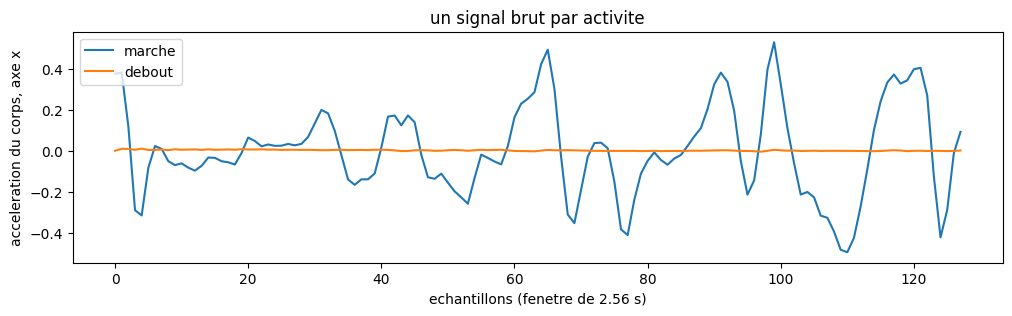

In [15]:
plt.figure(figsize=(12, 3))
for label, nom in [(1, "marche"), (5, "debout")]:
    idx = np.where(ys == label)[0][0]
    plt.plot(Xs[idx, :128], label=nom)
plt.xlabel("echantillons (fenetre de 2.56 s)")
plt.ylabel("acceleration du corps, axe x")
plt.title("un signal brut par activite")
plt.legend()
plt.show()

## 2. decoupage par sujet

les fenetres se recouvrent a 50 pourcent, donc deux fenetres voisines du meme sujet partagent des donnees.
on garde 4 sujets source pour le test source, et on separe les 9 sujets cible en 6 pour l'adaptation et 3 pour le test cible.

In [16]:
Xs_train, ys_train, Xs_test, ys_test, Xt_train, yt_train, Xt_test, yt_test = split_har(
    Xs, ys, subj_s, Xt, yt, subj_t)

len(Xs_train), len(Xs_test), len(Xt_train), len(Xt_test)

(5867, 1485, 1848, 1099)

## 3. source vers source et source vers cible

In [17]:
r_source_source = predict("classification", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("classification", Xs_train, ys_train, Xt_test, yt_test)
r_cible_cible = predict("classification", Xt_train, yt_train, Xt_test, yt_test)

print("source -> source :", round(r_source_source["accuracy"], 3))
print("source -> cible  :", round(r_source_cible["accuracy"], 3))
print("cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

source -> source : 0.639
source -> cible  : 0.663
cible  -> cible  : 0.555


## 4. combien de donnees cible pour un bon modele

on part du modele source, on ajoute des donnees cible a l'entrainement, et on mesure sur le test cible.

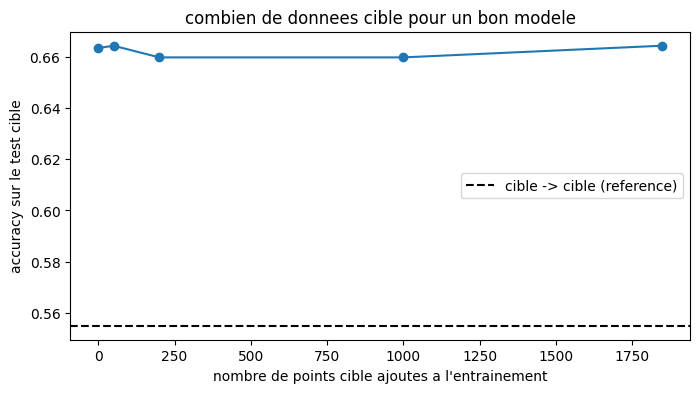

In [18]:
n_values = [0, 50, 200, 1000, len(Xt_train)]
acc_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xt_train[:n]])
        y_train = np.concatenate([ys_train, yt_train[:n]])
    acc_courbe.append(predict("classification", X_train, y_train, Xt_test, yt_test)["accuracy"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, acc_courbe, marker="o")
plt.axhline(r_cible_cible["accuracy"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("accuracy sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 5. courbes d'apprentissage separees (source et cible)

In [ ]:
n_values = [20, 30, 50, 75, 100, 150, 200, 300, 500, 750, 1000, 1500, 1848, 3000, len(Xs_train)]
ns_source, acc_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "classification", n_values)
ns_cible, acc_cible = courbe_apprentissage(Xt_train, yt_train, Xt_test, yt_test, "classification", n_values)
ns_transfert, acc_transfert = courbe_apprentissage(Xs_train, ys_train, Xt_test, yt_test, "classification", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, acc_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, acc_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, acc_transfert, marker="o", label="transfert (train source -> test cible)")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("accuracy")
plt.title("courbes d'apprentissage separees")
plt.legend()
plt.show()

## 6. equilibrage : autant de sujets en source qu'en cible

la source compte 21 sujets et la cible 9, donc le modele source s'entraine sur beaucoup plus de monde. son avantage peut venir de cette quantite de donnees et non d'une absence de shift. pour trancher, on ne garde que 9 sujets source, decoupes comme la cible en 6 pour l'entrainement et 3 pour le test. le choix des 9 sujets influe sur le resultat, on repete donc sur plusieurs tirages et on moyenne.

In [20]:
n_tirages = 5
rng = np.random.default_rng(0)
acc_ss, acc_sc = [], []

for k in range(n_tirages):
    tirage = list(rng.permutation(sorted(set(subj_s)))[:9])
    tr, te = tirage[:6], tirage[6:]
    Xa, ya = Xs[np.isin(subj_s, tr)], ys[np.isin(subj_s, tr)]
    Xb, yb = Xs[np.isin(subj_s, te)], ys[np.isin(subj_s, te)]
    a = predict("classification", Xa, ya, Xb, yb)["accuracy"]
    b = predict("classification", Xa, ya, Xt_test, yt_test)["accuracy"]
    acc_ss.append(a)
    acc_sc.append(b)
    print(f"tirage {k} : {len(Xa)} fenetres   source -> source {a:.3f}   source -> cible {b:.3f}")

print()
print(f"equilibre 9 vs 9, moyenne sur {n_tirages} tirages")
print("  source -> source :", round(float(np.mean(acc_ss)), 3))
print("  source -> cible  :", round(float(np.mean(acc_sc)), 3))
print("  cible  -> cible  :", round(r_cible_cible["accuracy"], 3))

tirage 0 : 2160 fenetres   source -> source 0.528   source -> cible 0.601
tirage 1 : 1984 fenetres   source -> source 0.593   source -> cible 0.655
tirage 2 : 2043 fenetres   source -> source 0.599   source -> cible 0.613
tirage 3 : 2069 fenetres   source -> source 0.576   source -> cible 0.631
tirage 4 : 2052 fenetres   source -> source 0.634   source -> cible 0.645

equilibre 9 vs 9, moyenne sur 5 tirages
  source -> source : 0.586
  source -> cible  : 0.629
  cible  -> cible  : 0.555


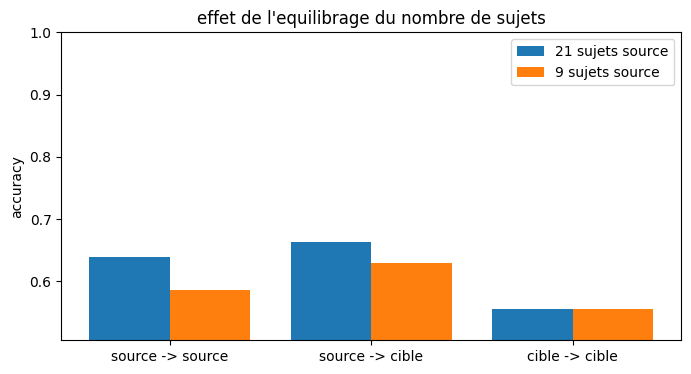

In [21]:
noms = ["source -> source", "source -> cible", "cible -> cible"]
desequilibre = [r_source_source["accuracy"], r_source_cible["accuracy"], r_cible_cible["accuracy"]]
equilibre = [float(np.mean(acc_ss)), float(np.mean(acc_sc)), r_cible_cible["accuracy"]]

x = np.arange(len(noms))
plt.figure(figsize=(8, 4))
plt.bar(x - 0.2, desequilibre, 0.4, label="21 sujets source")
plt.bar(x + 0.2, equilibre, 0.4, label="9 sujets source")
plt.xticks(x, noms)
plt.ylim(max(0.0, min(desequilibre + equilibre) - 0.05), 1.0)
plt.ylabel("accuracy")
plt.title("effet de l'equilibrage du nombre de sujets")
plt.legend()
plt.show()

## 7.ADAPT


feature_based,  CORAL

instance_based,  KMM

parameter_based,  RegularTransferLC

(1848, 6)
sans adaptation                  0.657
CORAL (feature)                  0.353
KMM (instance)                   0.62
RegularTransferLC (parametre)    0.625
cible -> cible                   0.652


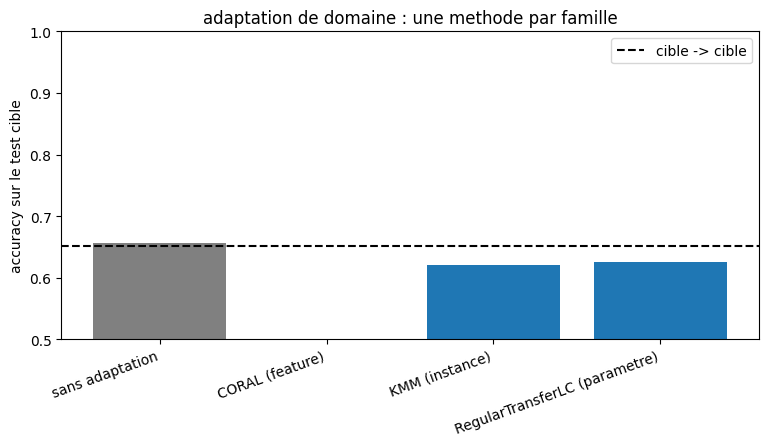

In [22]:
resultats = comparer_adapt("classification", Xs_train, ys_train, Xt_train, yt_train, Xt_test, yt_test)

for k, v in resultats.items():
    print(f"{k:32s} {round(v, 3)}")

barres_adapt(resultats, "adaptation de domaine : une methode par famille","accuracy sur le test cible", ylim=(0.5, 1.0))